## Exploratory Data Analysis
### DSCI 403
#### Clara Pugh and Chandler Bergstrom

This notebook loads in preprocessed data saved using preprocessing.ipynb, and investigates patterns using summary statistics and visualizations

In [2]:
# we should start with some summary statistics of the dataframe
# then make some plots:
    # sea surface temperature measured by ARGO vs by satellite (2D map of satellite SST with points of ARGO temp on top?)
    # temperature with depth of a few individual ARGO profiles
    # sea surface temperature as a function of time?? I'm not sure how useful that would be

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# load in the preprocessed data that we saved
full_df = pd.read_csv('clean_data_gulfstream_jan_2023.csv')
full_df['TIME'] = pd.to_datetime(full_df['TIME'])

surface_df = pd.read_csv('clean_SURFACE_data_gulfstream_jan_2023.csv')
surface_df['TIME'] = pd.to_datetime(surface_df['TIME'])

# as well as the full SST dataframe
sst_df = pd.read_csv('SST_only_gulfstream_jan_2023_not_clean.csv')

sst_df.head()

,time,zlev,latitude,longitude,sst,anom,err,ice
0,2023-01-01 12:00:00,0.0,25.125,-79.625,26.97,1.99,0.13,NaN
1,2023-01-01 12:00:00,0.0,25.125,-79.375,26.51,1.46,0.13,NaN
2,2023-01-01 12:00:00,0.0,25.125,-79.125,25.08,0.00,0.12,NaN
3,2023-01-01 12:00:00,0.0,25.125,-78.875,23.63,-1.49,0.12,NaN
4,2023-01-01 12:00:00,0.0,25.125,-78.625,23.16,-1.99,0.12,NaN


In [23]:
# .info() gives data type and non-null count for each column, and memory usage for the dataframe
print('data types, non-null counts, memory usage for full dataframe:\n')
print(full_df.info())

# .describe() gives some summary statistics to explore the data
print('\nsummary statistics for numeric columns of full dataframe:\n')
print(full_df.describe())

data types, non-null counts, memory usage for full dataframe:

<class 'pandas.DataFrame'>
RangeIndex: 97145 entries, 0 to 97144
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   index            97145 non-null  int64         
 1   N_PROF           97145 non-null  int64         
 2   N_LEVELS         97145 non-null  int64         
 3   CYCLE_NUMBER     97145 non-null  int64         
 4   DATA_MODE        97145 non-null  str           
 5   DIRECTION        97145 non-null  str           
 6   PLATFORM_NUMBER  97145 non-null  int64         
 7   PRES             97145 non-null  float64       
 8   PRES_ERROR       70420 non-null  float64       
 9   PSAL             97145 non-null  float64       
 10  PSAL_ERROR       70420 non-null  float64       
 11  TEMP             97145 non-null  float64       
 12  TEMP_ERROR       70420 non-null  float64       
 13  LATITUDE         97145 non-null  float6

In [6]:
# .info() gives data type and non-null count for each column, and memory usage for the dataframe
print('data types, non-null counts, memory usage for surface dataframe:\n')
print(surface_df.info())

# .describe() gives some summary statistics to explore the data
print('\nsummary statistics for numeric columns for surface dataframe:\n')
print(surface_df.describe())

data types, non-null counts, memory usage for surface dataframe:

<class 'pandas.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   PLATFORM_NUMBER  215 non-null    int64         
 1   CYCLE_NUMBER     215 non-null    int64         
 2   TIME             215 non-null    datetime64[us]
 3   LAT              215 non-null    float64       
 4   LON              215 non-null    float64       
 5   DATA_MODE        215 non-null    str           
 6   TEMP_SURF        215 non-null    float64       
 7   SST              215 non-null    float64       
 8   DIST_KM          215 non-null    float64       
 9   N_OBS            215 non-null    int64         
 10  DIFF             215 non-null    float64       
 11  OUTLIER          215 non-null    bool          
dtypes: bool(1), datetime64[us](1), float64(6), int64(3), str(1)
memory usage: 18.8 KB
None

summa

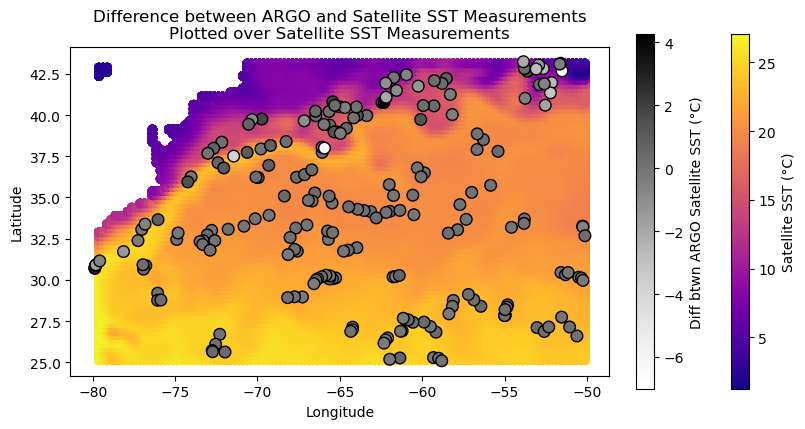

In [18]:
# plot: (Argo SST - satellite SST), overlain on satellite SST

fig, ax = plt.subplots(1,1,figsize=(8,6), layout='constrained')

# plot satellite SST
sst = ax.scatter(sst_df['longitude'], sst_df['latitude'], c=sst_df['sst'], cmap='plasma')
fig.colorbar(sst, ax=ax, label='Satellite SST (°C)', shrink=0.6)

# plot differences between temps
diffs = ax.scatter(surface_df['LON'], surface_df['LAT'], c=surface_df['DIFF'], cmap='Greys',s=70,edgecolors='black')
fig.colorbar(diffs, ax=ax, label='Diff btwn ARGO Satellite SST (°C)', shrink=0.6)

ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Difference between ARGO and Satellite SST Measurements\nPlotted over Satellite SST Measurements')

ax.set_aspect('equal', adjustable='box')
#ax.grid()

It looks like the highest differences in agreement are around where the gulf stream is, where there is a pretty abrupt change in SST. My initial hypothesis is that the satellite resolution does not have the resolution to capture smaller-scale eddies coming off the gulf stream

Next, I will plot some of the individual ARGO profiles, at four points. I will find the profiles closest to visually identified coordinates, with two near the gulf stream and two farther from the gulf stream

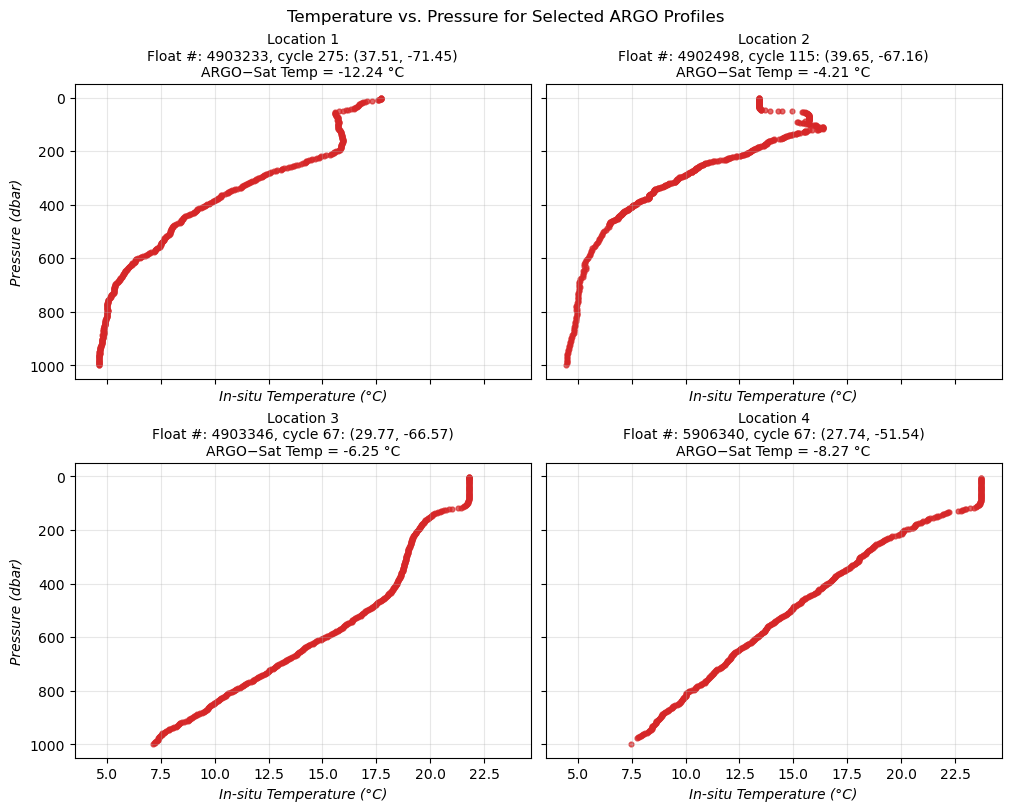

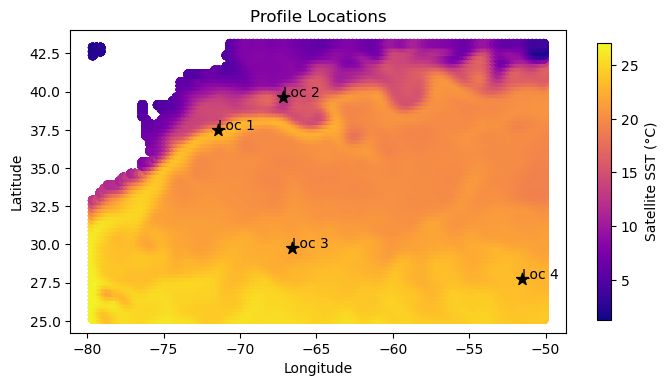

In [21]:
# one row per profile (float + cycle), with its location and TEMP_MINUS_SST
profiles = (full_df.groupby(['PLATFORM_NUMBER', 'CYCLE_NUMBER'])
            .agg(LAT=('LATITUDE', 'mean'), LON=('LONGITUDE', 'mean'),
                 TEMP_MINUS_SST=('TEMP_MINUS_SST', 'mean'))
            .reset_index())

targets = [(37.5, -71.5), (40.0, -68.0), (30.0, -67.0), (28.0, -52.0)]

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True, layout='constrained')

true_loc_list = []
loc_name = 0

for ax, (lat, lon) in zip(axes.flat, targets):
    # update loc_name
    loc_name +=1
    # closest profile to the target (longitude scaled by cos(lat) so distances are fair)
    dist = np.hypot(profiles['LAT'] - lat, (profiles['LON'] - lon) * np.cos(np.deg2rad(lat)))
    p = profiles.loc[dist.idxmin()]

    prof = full_df[(full_df['PLATFORM_NUMBER'] == p['PLATFORM_NUMBER']) &
                   (full_df['CYCLE_NUMBER'] == p['CYCLE_NUMBER'])]

    ax.scatter(prof['TEMP'], prof['PRES'], s=12, c='tab:red', alpha=0.7)
    ax.set_title(f"Location {loc_name}\nFloat #: {int(p['PLATFORM_NUMBER'])}, cycle {int(p['CYCLE_NUMBER'])}: "
                 f"({p['LAT']:.2f}, {p['LON']:.2f})\nARGO−Sat Temp = {p['TEMP_MINUS_SST']:.2f} °C", fontsize=10)
    ax.grid(alpha=0.3)
    true_loc_list.append([p['LAT'],p['LON']])

axes[0, 0].invert_yaxis()   # axes are shared, so this flips all four (pressure increases downward)
for ax in axes[0, :]:
    ax.set_xlabel('In-situ Temperature (°C)', style='italic')
for ax in axes[1, :]:
    ax.set_xlabel('In-situ Temperature (°C)', style='italic')
for ax in axes[:, 0]:
    ax.set_ylabel('Pressure (dbar)', style='italic')

fig.suptitle('Temperature vs. Pressure for Selected ARGO Profiles')
plt.show()




### and plot where they are on the map
fig, ax = plt.subplots(1,1,figsize=(8,6))

# plot satellite SST
sst = ax.scatter(sst_df['longitude'], sst_df['latitude'], c=sst_df['sst'], cmap='plasma')
fig.colorbar(sst, ax=ax, label='Satellite SST (°C)', shrink=0.6)

# plot the float locations
loc_name=0
for latlon in true_loc_list:
    loc_name+=1 #update loc name
    lat = latlon[0]
    lon = latlon[1]
    plt.scatter(lon, lat, s=80, color='black', marker='*')
    plt.annotate(f'Loc {loc_name}', xy=(lon, lat))
    
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Profile Locations')
ax.set_aspect('equal', adjustable='box')